In [2]:
from pathlib import Path

# Project paths
PROJECT_ROOT = Path.cwd()
DATASET_ROOT = PROJECT_ROOT / "dataset" / "CRACK500"
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "eda" / "crack500"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATASET_ROOT.exists())
print("Output folder:", OUTPUT_ROOT)

Project root: c:\Users\Rakshitha L\OneDrive\Desktop\InfraScan
Dataset exists: True
Output folder: c:\Users\Rakshitha L\OneDrive\Desktop\InfraScan\outputs\eda\crack500


In [3]:

from pathlib import Path
import pandas as pd

# Find all immediate subfolders of CRACK500
folder_summary = []

for folder in sorted(DATASET_ROOT.iterdir()):
    if folder.is_dir():
        files = [f for f in folder.rglob("*") if f.is_file()]

        folder_summary.append({
            "Folder": folder.name,
            "Total Files": len(files),
            "JPG Images": sum(f.suffix.lower() == ".jpg" for f in files),
            "PNG Files": sum(f.suffix.lower() == ".png" for f in files),
            "TXT Files": sum(f.suffix.lower() == ".txt" for f in files),
        })

folder_summary_df = pd.DataFrame(folder_summary)
display(folder_summary_df)


,Folder,Total Files,JPG Images,PNG Files,TXT Files
0,fphb_testresult,2248,0,1124,0
1,testcrop,2248,1124,1124,0
2,testdata,600,200,200,200
3,traincrop,3792,1896,1896,0
4,traindata,800,250,250,300
5,valcrop,696,348,348,0
6,valdata,100,50,50,0


In [4]:
data_folders = {
    "traincrop": DATASET_ROOT / "traincrop" / "traincrop",
    "testcrop": DATASET_ROOT / "testcrop" / "testcrop",
    "valcrop": DATASET_ROOT / "valcrop" / "valcrop",
    "traindata": DATASET_ROOT / "traindata" / "traindata",
    "testdata": DATASET_ROOT / "testdata" / "testdata",
    "valdata": DATASET_ROOT / "valdata" / "valdata",
}

print("Folders configured:", len(data_folders))

for name, path in data_folders.items():
    print(name, "-> Exists:", path.exists())

Folders configured: 6
traincrop -> Exists: True
testcrop -> Exists: True
valcrop -> Exists: True
traindata -> Exists: True
testdata -> Exists: True
valdata -> Exists: True


In [5]:
pair_counts = []

for name, path in data_folders.items():
    jpg_names = {f.stem for f in path.glob("*.jpg")}
    png_names = {f.stem for f in path.glob("*.png")}

    # Crop folders use identical names.
    # Original data folders use the _mask suffix.
    if name.endswith("crop"):
        mask_names = png_names
    else:
        mask_names = {
            stem[:-5] for stem in png_names
            if stem.endswith("_mask")
        }

    pair_counts.append({
        "Folder": name,
        "JPG Images": len(jpg_names),
        "Matching Pairs": len(jpg_names & mask_names),
        "JPG Without Mask": len(jpg_names - mask_names),
    })

pair_counts_df = pd.DataFrame(pair_counts)
display(pair_counts_df)

,Folder,JPG Images,Matching Pairs,JPG Without Mask
0,traincrop,1896,1896,0
1,testcrop,1124,1124,0
2,valcrop,348,348,0
3,traindata,250,250,0
4,testdata,200,200,0
5,valdata,50,50,0


In [6]:
from PIL import Image

dimension_results = []

for name, path in data_folders.items():
    for image_path in path.glob("*.jpg"):
        if name.endswith("crop"):
            mask_path = path / (image_path.stem + ".png")
        else:
            mask_path = path / (image_path.stem + "_mask.png")

        if mask_path.exists():
            with Image.open(image_path) as img:
                image_size = img.size

            with Image.open(mask_path) as mask:
                mask_size = mask.size

            dimension_results.append({
                "Folder": name,
                "Image": image_path.name,
                "Image Size": image_size,
                "Mask Size": mask_size,
                "Dimensions Match": image_size == mask_size
            })

dimension_df = pd.DataFrame(dimension_results)

print("Total image-mask pairs checked:", len(dimension_df))
print("Matching dimensions:", dimension_df["Dimensions Match"].sum())
print("Dimension mismatches:", (~dimension_df["Dimensions Match"]).sum())

Total image-mask pairs checked: 3868
Matching dimensions: 3865
Dimension mismatches: 3


In [7]:
mismatches_df = dimension_df[
    dimension_df["Dimensions Match"] == False
]

display(mismatches_df)

,Folder,Image,Image Size,Mask Size,Dimensions Match
3470,traindata,20160326_144512.jpg,"(1440, 2560)","(2560, 1440)",False
3472,traindata,20160326_150319.jpg,"(1440, 2560)","(2560, 1440)",False
3572,traindata,20160330_170428.jpg,"(1440, 2560)","(2560, 1440)",False


In [8]:
from PIL import Image

for _, row in mismatches_df.iterrows():
    path = data_folders[row["Folder"]]
    image_path = path / row["Image"]
    mask_path = path / (image_path.stem + "_mask.png")

    with Image.open(image_path) as img:
        image_orientation = img.getexif().get(274, "Not set")

    with Image.open(mask_path) as mask:
        mask_orientation = mask.getexif().get(274, "Not set")

    print(row["Image"])
    print("  Image EXIF orientation:", image_orientation)
    print("  Mask EXIF orientation:", mask_orientation)

20160326_144512.jpg
  Image EXIF orientation: 1
  Mask EXIF orientation: Not set
20160326_150319.jpg
  Image EXIF orientation: 1
  Mask EXIF orientation: Not set
20160330_170428.jpg
  Image EXIF orientation: 1
  Mask EXIF orientation: Not set


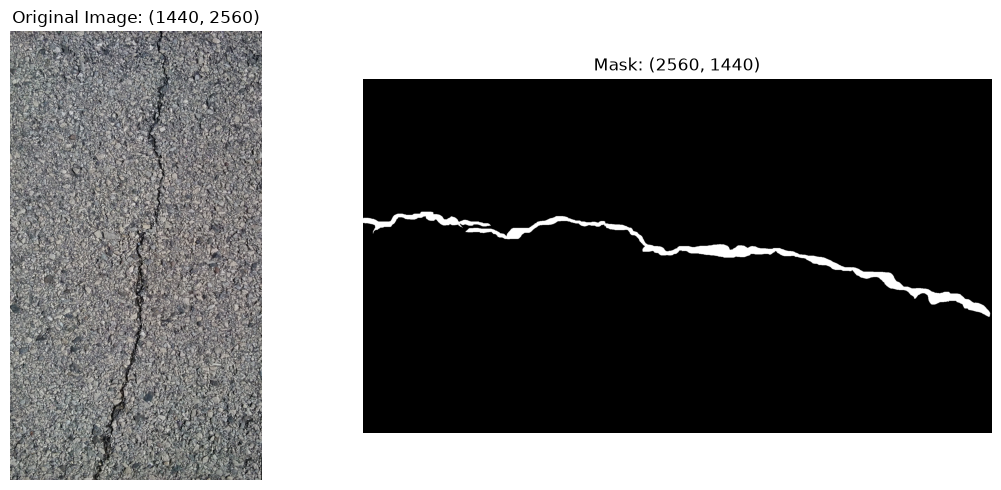

In [9]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

folder = data_folders["traindata"]
filename = "20160326_144512.jpg"

image_path = folder / filename
mask_path = folder / (Path(filename).stem + "_mask.png")

with Image.open(image_path) as img:
    image = img.copy()

with Image.open(mask_path) as img:
    mask = img.copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image)
axes[0].set_title(f"Original Image: {image.size}")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title(f"Mask: {mask.size}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [10]:
from PIL import Image

unreadable = []

for name, folder in data_folders.items():
    for path in folder.glob("*"):
        if path.suffix.lower() in [".jpg", ".png"]:
            try:
                with Image.open(path) as img:
                    img.verify()
            except Exception:
                unreadable.append((name, path.name))

print("Images checked:", sum(
    1 for folder in data_folders.values()
    for p in folder.glob("*")
    if p.suffix.lower() in [".jpg", ".png"]
))
print("Unreadable files:", len(unreadable))
print(unreadable[:10])

Images checked: 7736
Unreadable files: 0
[]


In [11]:
import pandas as pd
from PIL import Image

stats = []

for name, folder in data_folders.items():
    for path in folder.glob("*"):
        if path.suffix.lower() not in [".jpg", ".png"]:
            continue

        with Image.open(path) as img:
            width, height = img.size

        stats.append({
            "Folder": name,
            "File": path.name,
            "Type": path.suffix.lower(),
            "Width": width,
            "Height": height,
            "Size_KB": round(path.stat().st_size / 1024, 2)
        })

stats_df = pd.DataFrame(stats)

display(stats_df.groupby(["Folder", "Type"]).agg(
    File_Count=("File", "count"),
    Unique_Dimensions=("Width", "nunique"),
    Average_Size_KB=("Size_KB", "mean"),
    Min_Size_KB=("Size_KB", "min"),
    Max_Size_KB=("Size_KB", "max")
).round(2))

File_Count  Unique_Dimensions  Average_Size_KB  Min_Size_KB  \
Folder    Type                                                                
testcrop  .jpg        1124                  2            60.25        27.55   
          .png        1124                  2             0.91         0.19   
testdata  .jpg         200                  5          2769.95      1355.54   
          .png         200                  5             8.64         1.06   
traincrop .jpg        1896                  3            58.21        23.55   
          .png        1896                  3             0.89         0.17   
traindata .jpg         250                  3          2351.09      1250.45   
          .png         250                  3             7.67         2.52   
valcrop   .jpg         348                  3            57.38        32.63   
          .png         348                  3             0.86         0.19   
valdata   .jpg          50                  3          2223.88      1603.01   
          .png          50                  3             6.81         2.39   

                Max_Size_KB  
Folder    Type               
testcrop  .jpg        86.41  
          .png         3.74  
testdata  .jpg      6505.87  
          .png        39.58  
traincrop .jpg       120.06  
          .png         2.59  
traindata .jpg      5340.96  
          .png        22.41  
valcrop   .jpg       115.35  
          .png         2.44  
valdata   .jpg      3933.00  
          .png        13.83

In [12]:
# Save detailed image statistics
stats_df.to_csv(
    OUTPUT_ROOT / "crack500_image_statistics.csv",
    index=False
)

# Save image-mask pairing results
pair_counts_df.to_csv(
    OUTPUT_ROOT / "crack500_pairing_summary.csv",
    index=False
)

# Save dimension validation results
dimension_df.to_csv(
    OUTPUT_ROOT / "crack500_dimension_validation.csv",
    index=False
)

# Save folder summary
folder_summary_df.to_csv(
    OUTPUT_ROOT / "crack500_folder_summary.csv",
    index=False
)

print("CSV files saved successfully:")
for file in sorted(OUTPUT_ROOT.glob("*.csv")):
    print(file.name)

CSV files saved successfully:
crack500_dimension_validation.csv
crack500_folder_summary.csv
crack500_image_statistics.csv
crack500_pairing_summary.csv


In [13]:
annotation_summary = []

for name, folder in data_folders.items():
    txt_files = list(folder.glob("*.txt"))

    annotation_summary.append({
        "Folder": name,
        "TXT Files": len(txt_files),
        "Sample TXT Files": [f.name for f in txt_files[:5]]
    })

annotation_df = pd.DataFrame(annotation_summary)
display(annotation_df)

,Folder,TXT Files,Sample TXT Files
0,traincrop,0,[]
1,testcrop,0,[]
2,valcrop,0,[]
3,traindata,300,"[20160222_080850_mask.txt, 20160222_081011_mas..."
4,testdata,200,"[20160222_080933_mask.txt, 20160222_081839_mas..."
5,valdata,0,[]


In [14]:
annotation_matching = []

for name in ["traindata", "testdata"]:
    folder = data_folders[name]

    jpg_stems = {p.stem for p in folder.glob("*.jpg")}
    txt_stems = {
        p.stem.removesuffix("_mask")
        for p in folder.glob("*.txt")
    }

    annotation_matching.append({
        "Folder": name,
        "JPG Images": len(jpg_stems),
        "TXT Files": len(list(folder.glob("*.txt"))),
        "Images With TXT": len(jpg_stems & txt_stems),
        "Images Without TXT": len(jpg_stems - txt_stems),
        "TXT Without Image": len(txt_stems - jpg_stems)
    })

annotation_matching_df = pd.DataFrame(annotation_matching)
display(annotation_matching_df)

,Folder,JPG Images,TXT Files,Images With TXT,Images Without TXT,TXT Without Image
0,traindata,250,300,250,0,50
1,testdata,200,200,200,0,0


In [15]:
annotation_matching_df.to_csv(
    OUTPUT_ROOT / "crack500_annotation_matching.csv",
    index=False
)

annotation_df.to_csv(
    OUTPUT_ROOT / "crack500_annotation_summary.csv",
    index=False
)

print("Annotation CSV files saved:")
print("crack500_annotation_matching.csv")
print("crack500_annotation_summary.csv")

Annotation CSV files saved:
crack500_annotation_matching.csv
crack500_annotation_summary.csv


In [16]:
summary = """CRACK500 EDA SUMMARY

Image-mask pairs checked: 3868
Matching dimensions: 3865
Dimension mismatches: 3
Unreadable image/mask files: 0

Dimension mismatches:
- 20160326_144512.jpg
- 20160326_150319.jpg
- 20160330_170428.jpg

TXT annotation matching:
- traindata: 250 images matched, 50 unmatched TXT filenames
- testdata: 200 images matched, 0 unmatched TXT filenames

Original dataset files were not modified.
"""

summary_path = OUTPUT_ROOT / "crack500_eda_summary.txt"
summary_path.write_text(summary, encoding="utf-8")

print("Summary saved:", summary_path.name)
print("\nOutput files:")
for file in sorted(OUTPUT_ROOT.iterdir()):
    if file.is_file():
        print(file.name)

Summary saved: crack500_eda_summary.txt

Output files:
crack500_annotation_matching.csv
crack500_annotation_summary.csv
crack500_dimension_validation.csv
crack500_eda_summary.txt
crack500_folder_summary.csv
crack500_image_statistics.csv
crack500_pairing_summary.csv


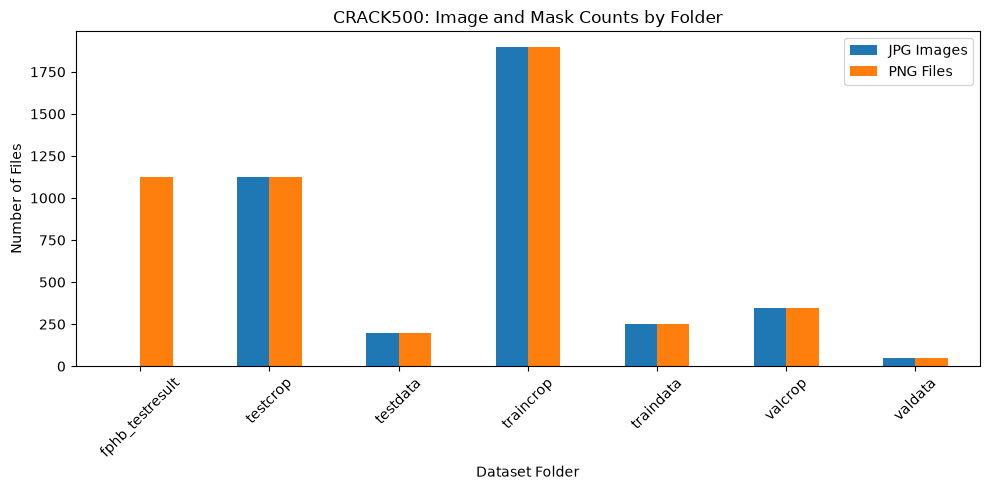

In [17]:
import matplotlib.pyplot as plt

folder_counts = folder_summary_df.set_index("Folder")[
    ["JPG Images", "PNG Files"]
]

folder_counts.plot(kind="bar", figsize=(10, 5))

plt.title("CRACK500: Image and Mask Counts by Folder")
plt.xlabel("Dataset Folder")
plt.ylabel("Number of Files")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "crack500_folder_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

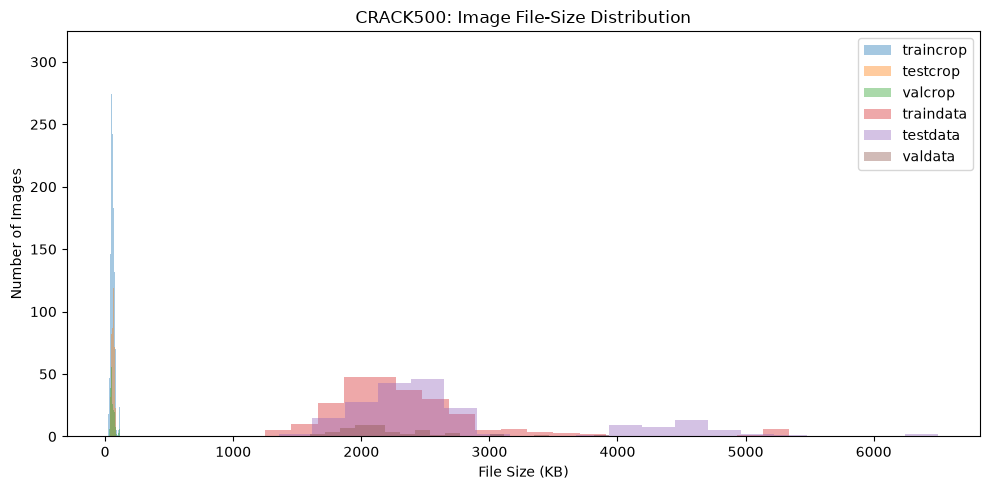

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for folder_name in stats_df["Folder"].unique():
    image_sizes = stats_df[
        (stats_df["Folder"] == folder_name) &
        (stats_df["Type"] == ".jpg")
    ]["Size_KB"]

    plt.hist(image_sizes, bins=20, alpha=0.4, label=folder_name)

plt.title("CRACK500: Image File-Size Distribution")
plt.xlabel("File Size (KB)")
plt.ylabel("Number of Images")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "crack500_image_size_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

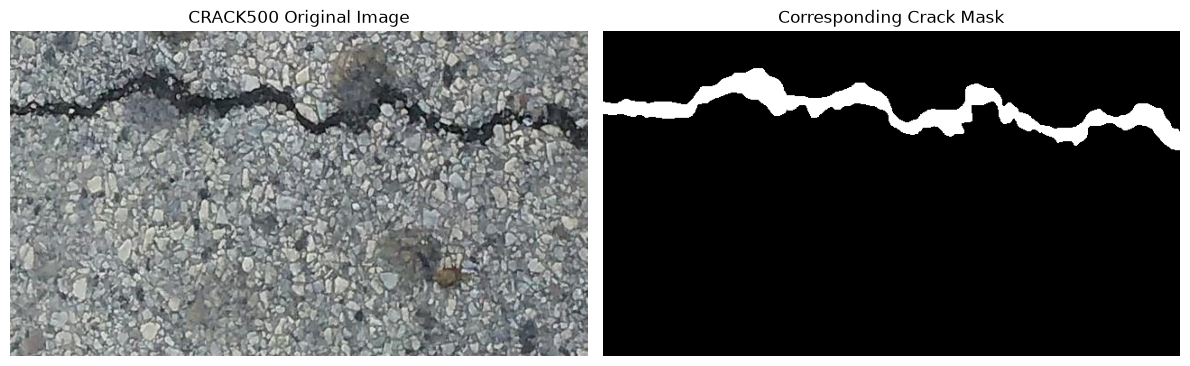

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

folder = data_folders["traincrop"]

image_path = next(folder.glob("*.jpg"))
mask_path = folder / (image_path.stem + ".png")

with Image.open(image_path) as img:
    image = img.copy()

with Image.open(mask_path) as img:
    mask = img.copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image)
axes[0].set_title("CRACK500 Original Image")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Corresponding Crack Mask")
axes[1].axis("off")

plt.tight_layout()
plt.savefig(
    OUTPUT_ROOT / "crack500_sample_image_mask.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [20]:
print("CRACK500 EDA OUTPUT FILES")
print("-" * 40)

for file in sorted(OUTPUT_ROOT.iterdir()):
    if file.is_file():
        print(f"{file.name} — {file.stat().st_size / 1024:.2f} KB")

print("\nTotal files:", sum(
    1 for file in OUTPUT_ROOT.iterdir() if file.is_file()
))

CRACK500 EDA OUTPUT FILES
----------------------------------------
crack500_annotation_matching.csv — 0.13 KB
crack500_annotation_summary.csv — 0.40 KB
crack500_dimension_validation.csv — 259.38 KB
crack500_eda_summary.txt — 0.42 KB
crack500_folder_counts.png — 116.78 KB
crack500_folder_summary.csv — 0.23 KB
crack500_image_size_distribution.png — 95.59 KB
crack500_image_statistics.csv — 425.13 KB
crack500_pairing_summary.csv — 0.17 KB
crack500_sample_image_mask.png — 1934.76 KB

Total files: 10


In [21]:
from pathlib import Path

project_root = Path.cwd()
sdnet_output = project_root / "outputs" / "eda"

print("SDNET2018 EDA output files:")
for file in sorted(sdnet_output.rglob("*")):
    if file.is_file() and "crack500" not in str(file).lower():
        print(file.relative_to(project_root))

SDNET2018 EDA output files:
outputs\eda\sdnet_category_counts.csv
outputs\eda\sdnet_category_distribution.png
outputs\eda\sdnet_class_distribution.csv
outputs\eda\sdnet_class_distribution.png
outputs\eda\sdnet_eda_summary.txt
outputs\eda\sdnet_image_details.csv


In [23]:
from pathlib import Path

project_root = Path.cwd()
sdnet_summary = project_root / "outputs" / "eda" / "sdnet_eda_summary.txt"
crack_summary = (
    project_root / "outputs" / "eda" / "crack500" / "crack500_eda_summary.txt"
)

print("===== SDNET2018 EDA SUMMARY =====")
print(sdnet_summary.read_text(encoding="utf-8"))

print("\n===== CRACK500 EDA SUMMARY =====")
print(crack_summary.read_text(encoding="utf-8"))

===== SDNET2018 EDA SUMMARY =====

SDNET2018 EXPLORATORY DATA ANALYSIS

1. Total Images: 56092

2. Category Distribution:
Category  Image Count
      CD         2025
      UD        11595
      CP         2608
      UP        21726
      CW         3851
      UW        14287

3. Cracked vs Uncracked Distribution:
    Class  Image Count  Percentage
  Cracked         8484   15.125152
Uncracked        47608   84.874848

4. Image File Size Statistics:
count    56092.000000
mean         9.240764
std          3.818049
min          1.780000
25%          6.200000
50%          8.080000
75%         12.180000
max         21.910000

5. Image Dimensions:
One sample image from each of the six categories
was checked. All sampled images were 256 x 256 pixels.

6. Image Readability:
100 images were checked for readability.
Unreadable images found in this sample: 0.

Note: Dimension and readability checks were sample-based,
not full-dataset validation.


===== CRACK500 EDA SUMMARY =====
CRACK500 EDA SUM

In [24]:
from pathlib import Path

project_root = Path.cwd()
output_folder = project_root / "outputs" / "eda"
output_folder.mkdir(parents=True, exist_ok=True)

report = """
INFRASCAN - COMBINED DATASET EDA REPORT
=======================================

1. SDNET2018 DATASET
--------------------
Total images: 56,092

Cracked images: 8,484 (15.13%)
Uncracked images: 47,608 (84.87%)

Categories:
CD: 2,025
UD: 11,595
CP: 2,608
UP: 21,726
CW: 3,851
UW: 14,287

Mean image file size: 9.24 KB
Minimum image file size: 1.78 KB
Maximum image file size: 21.91 KB

Sampled dimensions: 256 x 256 pixels
Readability: 100 sampled images checked; zero unreadable.


2. CRACK500 DATASET
-------------------
Image-mask pairs checked: 3,868
Pairs with matching dimensions: 3,865
Dimension mismatches: 3
Unreadable image/mask files: 0

All three dimension mismatches are in traindata:
- 20160326_144512.jpg
- 20160326_150319.jpg
- 20160330_170428.jpg

TXT annotation matching:
- traindata: 250 images matched; 50 TXT filenames unmatched
- testdata: 200 images matched; zero TXT filenames unmatched

Original dataset files were not modified.


3. COMBINED FINDINGS
--------------------
SDNET2018 provides cracked and uncracked images across six
categories and has a class imbalance: 84.87% uncracked versus
15.13% cracked.

CRACK500 provides image-mask pairs suitable for crack
segmentation analysis. Three pairs require dimension review,
and 50 training TXT filenames require further investigation.

SDNET2018 dimension and readability checks were sample-based.
CRACK500 image-mask dimension validation covered all 3,868 pairs.


4. RECOMMENDED FOLLOW-UP
------------------------
- Investigate the three CRACK500 dimension mismatches.
- Review the 50 unmatched CRACK500 training TXT filenames.
- Preserve original dataset files.
- Validate preprocessing and dataset compatibility before training.
"""

report_path = output_folder / "InfraScan_Combined_EDA_Report.txt"
report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("Combined report saved:", report_path)

Combined report saved: c:\Users\Rakshitha L\OneDrive\Desktop\InfraScan\outputs\eda\InfraScan_Combined_EDA_Report.txt
